# Poate un meta-model să bată prior-ul? Un sistem construit, înghețat și testat pe date nevăzute

**Scopul.** Pentru cele patru strategii primare din `quant_forge.strategies` (RSI, Donchian, TIS, SuperTrend), cu
parametrii impliciți, pe 20 de active spot Binance cu bare de 4h, căutăm un sistem care să extragă informație din
features și să îmbunătățească strategia **peste prior**. Prior-ul înseamnă două lucruri:

* pentru **probabilitate**: rata de câștig istorică a strategiei (un meta-model trebuie să aibă log loss mai mic);
* pentru **strategie**: a lua fiecare semnal cu aceeași mărime (un sistem trebuie să aibă Sharpe mai mare și, ca filtru,
  să bată o selecție aleatoare cu aceeași rată de acceptare).

**Ce știam dinainte.** Notebook-urile anterioare (`solid/cross_asset_transfer_meta_labeling.ipynb`, grid-ul multi-config,
feature engineering) au arătat că niciun meta-model nu bate rata de bază pe 2021-09 → 2026-09. Toată acea perioadă a fost
deja folosită de multe ori, deci orice „succes” găsit pe ea ar fi suspect de supra-selecție.

**De aceea, protocolul de aici este partea cea mai importantă.**

| Perioadă | Interval | Rol |
|---|---|---|
| **A** | 2017-09 → 2021-08 | **nevăzută** de orice experiment anterior; test final |
| **B** | 2021-09 → 2026-08 | dezvoltare (deja folosită anterior); aici se explorează și se alege sistemul |
| **C** | 2026-09 → 2026-11-19 | **date noi**, apărute după toate experimentele; test final |

Sistemul se dezvoltă **numai pe B** (inclusiv antrenarea: în dezvoltare nu se folosesc tranzacții din A), apoi se
**îngheață** într-o specificație scrisă, și abia apoi rulează o singură dată pe A și pe C. Perioadele A și C sunt posibile
pentru că barele de 4h din API-ul public Binance sunt identice cu cele din pipeline-ul `cryptods` (verificat mai jos), iar
Binance are istorie din 2017.

**Ce sugerează literatura** (de unde vin ipotezele):

* Meta-labeling-ul (López de Prado, *Advances in Financial Machine Learning*, 2018; Joubert, *Meta-Labeling: Theory and
  Framework*, JFDS 2022) are nevoie de informație pe care modelul primar nu o folosește, iar pentru dimensionare contează
  calibrarea probabilităților (Meyer, Barziy și Joubert, *Meta-Labeling: Calibration and Position Sizing*, JFDS 2023).
* Strategiile de momentum se prăbușesc în stări de „panică”: după scăderi ale pieței și în volatilitate ridicată
  (Daniel și Moskowitz, *Momentum Crashes*, JFE 2016) → features de stare a pieței și de volatilitate.
* Randamentul recent al unui factor/strategii anticipă randamentul următor (Gupta și Kelly, *Factor Momentum Everywhere*,
  JPM 2019) → features din istoricul recent al aceleiași strategii.
* În cripto, piața și momentum-ul transversal explică randamentele (Liu, Tsyvinski și Wu, *Common Risk Factors in
  Cryptocurrency*, JF 2022) → forța relativă a activului.
* Portofoliile gestionate după volatilitate au Sharpe mai mare (Moreira și Muir, JF 2017; Barroso și Santa-Clara, JFE 2015)
  → dimensionare invers proporțională cu volatilitatea.

**Rezultatul pe scurt** (detalii și cifre în concluziile de la final):

* **Un meta-model care să bată prior-ul ca probabilitate nu s-a găsit.** Sistemul ales pe B pierde pe perioada nevăzută A
  (+0.003 log loss față de prior), iar pe C (3 luni) nu se poate spune nimic.
* **Filtrul de volatilitate**, foarte bun pe B, **eșuează pe A**: e mai rău decât o selecție aleatoare. Este exact riscul
  notat înainte de test.
* **Ce funcționează este dimensionarea poziției invers proporțional cu volatilitatea activului**: Sharpe +0.33 pe B și
  **+0.41 [+0.09, +0.73] pe A**, robust la cozi, la măsura volatilității și pe ani. E singura componentă care deduce ceva util
  din features și îmbunătățește strategia peste „aceeași mărime pentru fiecare semnal”.

## Configurare

In [1]:
import json, sys, time, urllib.request, warnings, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "quant_forge/strategies").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
try:
    import quant_forge.strategies as qs
except ImportError:
    sys.path.insert(0, str(ROOT))
    import quant_forge.strategies as qs

KLINES_DIR = Path.home() / ".cache/quantforge/binance_klines_4h"     # cache; refilled from the public API if missing
PIPELINE_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"  # only used for the consistency check
ASSETS = ["BTC", "ETH", "BNB", "SOL", "XRP", "ADA", "AVAX", "BCH", "DOGE", "DOT", "LINK", "LTC", "UNI",
          "AAVE", "ATOM", "ETC", "FIL", "NEAR", "TRX", "XLM"]
TICKS = {"BTC": 1e-2, "ETH": 1e-2, "BNB": 1e-4, "SOL": 1e-4, "XRP": 1e-5, "ADA": 1e-5, "AVAX": 1e-4, "BCH": 1e-2,
         "DOGE": 1e-7, "DOT": 1e-4, "LINK": 1e-4, "LTC": 1e-2, "UNI": 1e-4, "AAVE": 1e-3, "ATOM": 1e-3, "ETC": 1e-4,
         "FIL": 1e-4, "NEAR": 1e-4, "TRX": 1e-5, "XLM": 1e-5}
DATA_END = pd.Timestamp("2026-11-19 00:00", tz="UTC")   # last bar end used (fixed for reproducibility)
WARMUP_DAYS = 30                                         # first days after listing are dropped
BAR = pd.Timedelta("4h")
FEE_BPS = 5.0
NOTIONAL = 10_000.0
N_BOOT = 2000

A_END = pd.Timestamp("2021-09-01", tz="UTC")             # A: decided before; B: decided after and exited before B_END
B_END = pd.Timestamp("2026-09-01", tz="UTC")             # C: decided after
WB = pd.to_datetime(["2023-09-01", "2024-03-01", "2024-09-01", "2025-03-01", "2025-09-01", "2026-03-01"], utc=True)
WA = pd.to_datetime(["2019-03-01", "2019-09-01", "2020-03-01", "2020-09-01", "2021-03-01"], utc=True)
WINDOWS_B = list(zip(WB, [*WB[1:], B_END]))
WINDOWS_A = list(zip(WA, [*WA[1:], A_END]))
WINDOWS_C = [(B_END, DATA_END)]

S = qs.Strategies
STRATEGIES = {S.RSI_CROSS_ABOVE: "RSI", S.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
              S.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS", S.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND"}
SS = list(STRATEGIES.values())
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## Date: bare de 4h din API-ul public Binance

Barele se descarcă o singură dată (`/api/v3/klines`, interval 4h) și se păstrează în cache. Prima lună după listarea
fiecărui activ este eliminată. `bar_seq` vine din grila de 4h, deci golurile din date (de exemplu oprirea Binance din
2018-02-08) rup segmentul, iar biblioteca de strategii repornește indicatorii. `complete = n_trades > 0`.

In [2]:
KLINE_COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time", "quote_volume", "n_trades",
              "taker_buy_base", "taker_buy_quote", "ignore"]


def fetch_klines(asset, start="2017-08-01"):
    rows, t = [], int(pd.Timestamp(start, tz="UTC").timestamp() * 1000)
    end_ms = int(DATA_END.timestamp() * 1000)
    while t < end_ms:
        url = f"https://api.binance.com/api/v3/klines?symbol={asset}USDT&interval=4h&startTime={t}&limit=1000"
        with urllib.request.urlopen(url, timeout=30) as r:
            batch = json.load(r)
        if not batch:
            break
        rows += batch
        t = batch[-1][0] + 1
        if len(batch) < 1000:
            break
        time.sleep(0.15)
    df = pd.DataFrame(rows, columns=KLINE_COLS).drop(columns="ignore")
    for c in ["open", "high", "low", "close", "volume", "quote_volume", "taker_buy_base", "taker_buy_quote"]:
        df[c] = df[c].astype(float)
    return df


def load_bars(asset):
    path = KLINES_DIR / f"{asset}USDT.parquet"
    k = pd.read_parquet(path) if path.exists() else None
    if k is None or pd.to_datetime(k["open_time"].max(), unit="ms", utc=True) + BAR < DATA_END:
        KLINES_DIR.mkdir(parents=True, exist_ok=True)
        k = fetch_klines(asset)
        k.to_parquet(path, index=False)
    start = pd.to_datetime(k["open_time"], unit="ms", utc=True)
    df = pd.DataFrame({"bar_start": start, "bar_end": start + BAR, "open": k["open"], "high": k["high"], "low": k["low"],
                       "close": k["close"], "volume": k["volume"], "quote_volume": k["quote_volume"],
                       "n_trades": k["n_trades"].astype(float), "taker_buy_base": k["taker_buy_base"]})
    df = df.loc[(df["bar_end"] <= DATA_END) & (df["bar_start"] >= start.iloc[0] + pd.Timedelta(days=WARMUP_DAYS))]
    df = df.set_index("bar_end", drop=False).rename_axis("t")
    df["bar_start_us"] = df["bar_start"].astype("int64") // 1000
    df["bar_end_us"] = df["bar_end"].astype("int64") // 1000
    df["bar_seq"] = ((df["bar_start"] - pd.Timestamp("2017-01-01", tz="UTC")) // BAR).astype("int64")
    df["complete"] = (df["n_trades"] > 0).astype(int)
    return df


bars = {a: load_bars(a) for a in ASSETS}
pd.DataFrame({"prima bară": {a: b.index.min() for a, b in bars.items()},
              "ultima bară": {a: b.index.max() for a, b in bars.items()},
              "bare": {a: len(b) for a, b in bars.items()},
              "bare lipsă din grilă": {a: int(b["bar_seq"].diff().gt(1).sum()) for a, b in bars.items()}})

,prima bară,ultima bară,bare,bare lipsă din grilă
BTC,2017-09-16 08:00:00+00:00,2026-11-19 00:00:00+00:00,20089,8
ETH,2017-09-16 08:00:00+00:00,2026-11-19 00:00:00+00:00,20089,8
BNB,2017-12-06 04:00:00+00:00,2026-11-19 00:00:00+00:00,19604,8
SOL,2020-09-10 08:00:00+00:00,2026-11-19 00:00:00+00:00,13565,0
XRP,2018-06-03 12:00:00+00:00,2026-11-19 00:00:00+00:00,18535,7
ADA,2018-05-17 08:00:00+00:00,2026-11-19 00:00:00+00:00,18638,7
AVAX,2020-10-22 08:00:00+00:00,2026-11-19 00:00:00+00:00,13313,0
BCH,2019-12-28 12:00:00+00:00,2026-11-19 00:00:00+00:00,15105,1
DOGE,2019-08-04 16:00:00+00:00,2026-11-19 00:00:00+00:00,15979,2
DOT,2020-09-18 00:00:00+00:00,2026-11-19 00:00:00+00:00,13519,0


### Verificare: barele Binance sunt identice cu cele din pipeline-ul `cryptods`

Pe perioada comună (2021-09 → 2026-09) comparăm OHLCV, numărul de tranzacții și dezechilibrul taker cu dataset-urile de 4h
folosite în notebook-urile anterioare. Dacă dataset-urile nu există local, celula doar raportează asta.

In [3]:
rows = {}
for a in ASSETS:
    found = sorted(PIPELINE_DIR.glob(f"{a}USDT_spot_time_4h_4h_20210901-20260901_*/time.parquet"))
    if not found:
        rows[a] = {"status": "dataset absent"}
        continue
    p = pd.read_parquet(found[0], columns=["bar_end_us", "open", "high", "low", "close", "volume", "n_trades",
                                           "aggr_imbalance_volume"])
    p.index = pd.to_datetime(p["bar_end_us"], unit="us", utc=True)
    j = p.join(bars[a][["open", "high", "low", "close", "volume", "n_trades", "taker_buy_base"]], rsuffix="_k", how="left")
    imb_k = 2 * j["taker_buy_base"] / j["volume_k"] - 1
    rows[a] = {"bare comune": int(j["open_k"].notna().sum()), "din": len(j),
               "max |Δ relativ| OHLCV": float(max(np.nanmax(np.abs(j[c] / j[c + "_k"] - 1))
                                                  for c in ["open", "high", "low", "close", "volume"])),
               "n_trades egale (%)": 100 * float((j["n_trades"] == j["n_trades_k"]).mean()),
               "corelație dezechilibru": float(np.corrcoef(j["aggr_imbalance_volume"], imb_k)[0, 1])}
pd.DataFrame(rows).T

,bare comune,din,max |Δ relativ| OHLCV,n_trades egale (%),corelație dezechilibru
BTC,10956.0,10956.0,0.0,100.0,1.0
ETH,10956.0,10956.0,0.0,100.0,1.0
BNB,10956.0,10956.0,0.0,100.0,1.0
SOL,10956.0,10956.0,0.0,100.0,1.0
XRP,10956.0,10956.0,0.0,100.0,1.0
ADA,10956.0,10956.0,0.0,100.0,1.0
AVAX,10956.0,10956.0,0.0,100.0,1.0
BCH,10956.0,10956.0,0.0,100.0,1.0
DOGE,10956.0,10956.0,0.0,100.0,1.0
DOT,10956.0,10956.0,0.0,100.0,1.0


## Features

Toate features sunt **adimensionale** și calculate doar din barele de până la bara semnalului inclusiv. Biblioteca le copiază
de pe bara semnalului (`context_columns`). Familii:

| Familie | Exemple | Ipoteza |
|---|---|---|
| `V` volatilitatea activului | vol. realizată 30 de zile, raport 1d/30d, lățime Bollinger, ATR/preț, percentila vol. pe 1 an | Daniel-Moskowitz, Moreira-Muir |
| `T` trend propriu | randamente 1/7/30/90 zile scalate la vol., distanța față de EMA50 în ATR, RSI 14, drawdown 90 zile | geometria semnalului |
| `M` starea pieței | indice egal ponderat al celor 20: randamente, vol., percentila vol., drawdown, breadth (fracție peste SMA50/200 zile), dispersie, altcoins vs BTC, corelația medie | „panic states” |
| `R` forță relativă | randament 7/30 zile minus mediana celor 20, rang transversal | Liu-Tsyvinski-Wu |
| `S` istoricul strategiei | rata de câștig a ultimelor 30/100 tranzacții închise ale aceleiași strategii, poziții deschise, semnale simultane | Gupta-Kelly |
| `F` flux taker | dezechilibrul taker, volum relativ | microstructură „lite” |
| `XV`, `XT`, `XF` ranguri transversale | rangul activului printre cele 20, la același moment, pentru features V/T/F | elimină componenta de regim |

Pentru SuperTrend, care are și short-uri, features direcționale sunt înmulțite cu `side`.

In [4]:
def wilder(a, n):
    a = np.asarray(a, float)
    out = np.full(len(a), np.nan)
    fin = np.flatnonzero(np.isfinite(a))
    if len(fin) and len(a) >= fin[0] + n:
        k = fin[0] + n - 1
        out[k] = a[fin[0]:k + 1].mean()
        for j in range(k + 1, len(a)):
            out[j] = out[j - 1] + (a[j] - out[j - 1]) / n if np.isfinite(a[j]) else out[j - 1]
    return out


def rsi(c, n):
    ch = c.diff()
    gain = pd.Series(wilder(ch.clip(lower=0).to_numpy(), n), index=c.index)
    loss = pd.Series(wilder((-ch).clip(lower=0).to_numpy(), n), index=c.index)
    return (100 * gain / (gain + loss)).mask((gain == 0) & (loss == 0), 50.0)


def own_features(g):
    o, h, l, c = g["open"], g["high"], g["low"], g["close"]
    f = pd.DataFrame(index=g.index)
    r = np.log(c).diff()
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    atr = pd.Series(wilder(tr.to_numpy(), 14), index=g.index)
    rv = lambda n: np.sqrt((r ** 2).rolling(n, min_periods=int(0.8 * n)).sum())
    rv1, rv7, rv30, rv90 = rv(6), rv(42), rv(180), rv(540)
    sig = rv30 / np.sqrt(180)
    f["v_rvol_ratio_1d_30d"] = np.log(rv1 / np.sqrt(6) / sig)
    f["v_rvol_ratio_7d_90d"] = np.log((rv7 / np.sqrt(42)) / (rv90 / np.sqrt(540)))
    f["v_rvol_30d"] = rv30
    f["v_rvol_pct_1y"] = rv7.rolling(2190, min_periods=540).rank(pct=True)
    f["v_bb_width"] = 4 * c.rolling(20).std(ddof=0) / c.rolling(20).mean()
    f["v_atr_rel"] = atr / c
    f["v_range_rel"] = (h - l) / c
    for k, name in [(6, "1d"), (42, "7d"), (180, "30d"), (540, "90d")]:
        f[f"t_ret_{name}_z"] = np.log(c / c.shift(k)) / (sig * np.sqrt(k))
        f[f"_ret_{name}"] = np.log(c / c.shift(k))
    ema50 = c.ewm(span=50, adjust=False, min_periods=50).mean()
    f["t_ema50_dist_atr"] = (c - ema50) / atr
    f["t_dd_90d"] = np.log(c / h.rolling(540, min_periods=300).max())
    f["t_up_90d"] = np.log(c / l.rolling(540, min_periods=300).min())
    f["t_sma200d_dist"] = np.log(c / c.rolling(1200, min_periods=900).mean())
    f["t_eff_20"] = c.diff(20) / c.diff().abs().rolling(20).sum()
    f["t_rsi14"] = rsi(c, 14) / 100
    f["f_taker_imb"] = 2 * g["taker_buy_base"] / g["volume"].where(g["volume"] > 0) - 1
    f["f_taker_imb_6"] = f["f_taker_imb"].rolling(6).mean()
    lq = np.log(g["quote_volume"].where(g["quote_volume"] > 0))
    f["f_qvol_rel_30d"] = lq - lq.rolling(180, min_periods=120).mean()
    f["_r"] = r
    for n, name, mp in [(300, "50d", 250), (1200, "200d", 900)]:
        sma = c.rolling(n, min_periods=mp).mean()
        f[f"_above_sma{name}"] = (c > sma).astype(float).where(sma.notna())
    return f


feats = {a: own_features(b) for a, b in bars.items()}

# market: equal-weighted index of the assets with data at t
R = pd.DataFrame({a: f["_r"] for a, f in feats.items()}).sort_index()
idx = R.index
mr = R.mean(axis=1).fillna(0.0)
cm = mr.cumsum()
mrv = lambda n: np.sqrt((mr ** 2).rolling(n, min_periods=int(0.8 * n)).sum())
msig = mrv(180) / np.sqrt(180)
mkt = pd.DataFrame(index=idx)
mkt["m_n_assets"] = R.notna().sum(axis=1)
for k, name in [(6, "1d"), (42, "7d"), (180, "30d"), (540, "90d"), (2190, "365d")]:
    mkt[f"m_ret_{name}"] = cm - cm.shift(k)
    mkt[f"m_ret_{name}_z"] = mkt[f"m_ret_{name}"] / (msig * np.sqrt(k))
mkt["m_rvol_30d"] = mrv(180)
mkt["m_rvol_ratio_7d_90d"] = np.log((mrv(42) / np.sqrt(42)) / (mrv(540) / np.sqrt(540)))
mkt["m_rvol_pct_1y"] = mrv(42).rolling(2190, min_periods=540).rank(pct=True)
mkt["m_dd_180d"] = cm - cm.rolling(1080, min_periods=540).max()
for name in ["50d", "200d"]:
    mkt[f"m_breadth_sma{name}"] = pd.DataFrame({a: f[f"_above_sma{name}"] for a, f in feats.items()}).reindex(idx).mean(axis=1)
R7 = pd.DataFrame({a: f["_ret_7d"] for a, f in feats.items()}).reindex(idx)
R30 = pd.DataFrame({a: f["_ret_30d"] for a, f in feats.items()}).reindex(idx)
mkt["m_dispersion_7d"] = R7.std(axis=1)
mkt["m_alt_vs_btc_30d"] = mkt["m_ret_30d"] - feats["BTC"]["_ret_30d"].reindex(idx)
mkt["b_ret_30d_z"] = feats["BTC"]["t_ret_30d_z"].reindex(idx)
mkt["b_rvol_ratio_1d_30d"] = feats["BTC"]["v_rvol_ratio_1d_30d"].reindex(idx)
CORR = pd.DataFrame({a: R[a].rolling(180, min_periods=150).corr(mr) for a in R})
mkt["m_avg_corr_30d"] = CORR.mean(axis=1)

# cross-sectional ranks (remove what is common to all assets at t)
XR = ["v_rvol_30d", "v_atr_rel", "v_bb_width", "v_rvol_ratio_1d_30d", "v_rvol_ratio_7d_90d", "v_range_rel",
      "t_ret_1d_z", "t_ret_7d_z", "t_rsi14", "t_ema50_dist_atr", "t_up_90d", "t_dd_90d", "t_eff_20",
      "f_qvol_rel_30d", "f_taker_imb_6"]
xr = {c: pd.DataFrame({a: feats[a][c] for a in ASSETS}).sort_index().rank(axis=1, pct=True) for c in XR}
for a in ASSETS:
    f = feats[a]
    for c in XR:
        f["xr_" + c[2:]] = xr[c][a].reindex(f.index)
    f["x_rs_7d"] = f["_ret_7d"] - R7.median(axis=1).reindex(f.index)
    f["x_rs_30d"] = f["_ret_30d"] - R30.median(axis=1).reindex(f.index)
    f["x_rank_30d"] = R30.rank(axis=1, pct=True)[a].reindex(f.index)
    f["x_corr_mkt_30d"] = CORR[a].reindex(f.index)
    f = f.join(mkt, how="left")
    bars[a] = bars[a].join(f.drop(columns=[c for c in f.columns if c.startswith("_")]))
FEATURE_COLS = [c for c in bars["BTC"].columns if c[:2] in ("v_", "t_", "f_", "x_", "m_", "b_") or c[:3] == "xr_"]
print(len(FEATURE_COLS), "features per bar")

61 features per bar


## Rularea strategiilor și istoricul strategiei

Parametri impliciți, `fee_bps=5`, `slippage_ticks=0`. Eticheta: `y = 1[trade_return > 0]`. Features `S` folosesc doar
tranzacțiile **închise strict înainte** de momentul deciziei.

In [5]:
LIB = {"RSI": ["rsi_value"],
       "DONCHIAN": ["adx_value", "di_diff", "long_breakout_atr", "ema_distance", "atr_rel"],
       "TIS": ["green_streak", "htf_green_streak"],
       "SUPERTREND": ["st_regime", "st_atr_ratio", "st_adx", "st_adapt_multiplier", "signal_score", "side"]}
frames = []
for strat, sname in STRATEGIES.items():
    for a, df in bars.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = qs.run_strategy(df, strat, fee_bps=FEE_BPS, slippage_ticks=0, tick_size=TICKS[a],
                                  context_columns=FEATURE_COLS)
        t = res.closed_trades_frame()
        lib = [c for c in LIB[sname] if c in t.columns and c != "side"]
        t = t[["side", "decision_time", "entry_time", "exit_time", "trade_status", "trade_return"] + lib + FEATURE_COLS].copy()
        t["strategy"], t["asset"] = sname, a
        frames.append(t)
trades = pd.concat(frames, ignore_index=True)
for c in ["decision_time", "entry_time", "exit_time"]:
    trades[c] = pd.to_datetime(trades[c], utc=True)
trades = trades.loc[trades["trade_status"].eq("closed")].sort_values(["decision_time", "strategy", "asset"]).reset_index(drop=True)
trades["y"] = trades["trade_return"].gt(0).astype(int)


def ns(x):
    return x.dt.tz_convert("UTC").dt.tz_localize(None).values.astype("datetime64[ns]").astype("int64")


def track_record(tr):
    out = pd.DataFrame(index=tr.index)
    clipped = tr["trade_return"].clip(-0.2, 0.2)
    for scope, groups in [("s", tr.groupby("strategy")), ("a", [("ALL", tr)])]:
        for _, g in groups:
            ex = g.sort_values("exit_time")
            et = ns(ex["exit_time"])
            yc = np.r_[0, ex["y"].cumsum().to_numpy()]
            rc = np.r_[0, clipped.loc[ex.index].cumsum().to_numpy()]
            k = np.searchsorted(et, ns(g["decision_time"]), side="left")     # closed strictly before t
            for n in ([30, 100] if scope == "s" else [100]):
                lo = np.maximum(k - n, 0)
                cnt = k - lo
                ok = cnt >= n // 2
                out.loc[g.index, f"{scope}_wr_{n}"] = np.where(ok, (yc[k] - yc[lo]) / np.maximum(cnt, 1), np.nan)
                if scope == "s":
                    out.loc[g.index, f"s_mr_{n}"] = np.where(ok, (rc[k] - rc[lo]) / np.maximum(cnt, 1), np.nan)
    for _, g in tr.groupby(["strategy", "asset"]):
        ex = g.sort_values("exit_time")
        et = ns(ex["exit_time"])
        yc = np.r_[0, ex["y"].cumsum().to_numpy()]
        k = np.searchsorted(et, ns(g["decision_time"]), side="left")
        lo = np.maximum(k - 10, 0)
        out.loc[g.index, "s_wr_asset_10"] = np.where(k - lo >= 5, (yc[k] - yc[lo]) / np.maximum(k - lo, 1), np.nan)
    for _, g in tr.groupby("strategy"):
        dt = ns(g["decision_time"])
        en, ex = np.sort(ns(g["entry_time"])), np.sort(ns(g["exit_time"]))
        out.loc[g.index, "s_open_positions"] = np.searchsorted(en, dt, side="right") - np.searchsorted(ex, dt, side="right")
        ds = np.sort(dt)
        out.loc[g.index, "s_signals_24h"] = (np.searchsorted(ds, dt, side="right")
                                             - np.searchsorted(ds, dt - 24 * 3600 * 10**9, side="right") - 1)
    out["s_open_positions"] = out["s_open_positions"] / tr["m_n_assets"]
    out["s_signals_24h"] = out["s_signals_24h"] / tr["m_n_assets"]
    return out


trades = trades.join(track_record(trades))
trades["period"] = np.select([trades["decision_time"] < A_END,
                              (trades["decision_time"] >= A_END) & (trades["exit_time"] < B_END),
                              trades["decision_time"] >= B_END], ["A", "B", "C"], "purjat")
pd.crosstab(trades["strategy"], trades["period"], margins=True, margins_name="total")

period,A,B,C,purjat,total
strategy,,,,,
DONCHIAN,637,1185,46,1,1869
RSI,1824,3252,119,0,5195
SUPERTREND,978,2495,113,7,3593
TIS,433,984,41,2,1460
total,3872,7916,319,10,12117


În perioada B numărul de tranzacții este practic același ca în notebook-ul anterior (RSI 3 252 față de 3 237, Donchian
1 185 față de 1 177, TIS 984 față de 976, SuperTrend 2 495 față de 2 490). Diferențele vin din istoria mai lungă de
încălzire a indicatorilor. Perioada A adaugă ~3 900 de tranzacții, iar C ~320.

## Instrumente de modelare și evaluare

* **Modele:** regresie logistică L2 cu imputare mediană și `QuantileTransformer` (robust la cozi) și
  `HistGradientBoosting` superficial (adâncime 2, 200 de iterații, frunze ≥ 80).
* **Walk-forward:** pentru o fereastră de test `[w0, w1)`, antrenarea folosește doar tranzacții **închise** înainte de `w0`.
* **Selecție internă:** C-ul regresiei logistice se alege pe 3 fold-uri temporale expandabile și purjate, în interiorul
  datelor de antrenare. Dacă niciun C nu bate prior-ul pe fold-urile interne, sistemul **se abține** și predicția e prior-ul.
* **Prior:** rata de câștig din antrenare a strategiei respective (constantă în fereastra de test).
* **Probabilitate:** Δ log loss per tranzacție față de prior; IC 95 % din bootstrap pe blocuri lunare.
* **Economie:** Sharpe-ul PnL-ului lunar (luna de ieșire, notional 10 000 USD × multiplicator), diferența față de „toate
  tranzacțiile, aceeași mărime” cu bootstrap lunar. Pentru filtre se raportează și **lift-ul față de selecția aleatoare** cu
  același număr de tranzacții acceptate pe strategie.

In [6]:
EPS = 1e-6
DIRECTIONAL = ("t_ret", "t_ema50", "t_sma200", "t_eff", "x_rs", "m_ret", "b_ret", "f_taker", "m_alt")
CENTERED = ("x_rank_30d", "m_breadth_sma50d", "m_breadth_sma200d", "t_rsi14", "xr_ret_1d_z", "xr_ret_7d_z", "xr_rsi14",
            "xr_ema50_dist_atr", "xr_eff_20", "xr_taker_imb_6")
XR_UNSIGNED = ("xr_rvol_30d", "xr_atr_rel", "xr_bb_width", "xr_rvol_ratio_1d_30d", "xr_rvol_ratio_7d_90d",
               "xr_range_rel", "xr_up_90d", "xr_dd_90d", "xr_qvol_rel_30d")
FAMILIES = {
    "V": ["v_rvol_ratio_1d_30d", "v_rvol_ratio_7d_90d", "v_rvol_30d", "v_rvol_pct_1y", "v_bb_width", "v_atr_rel", "v_range_rel"],
    "T": ["t_ret_1d_z", "t_ret_7d_z", "t_ret_30d_z", "t_ret_90d_z", "t_ema50_dist_atr", "t_dd_90d", "t_up_90d",
          "t_sma200d_dist", "t_eff_20", "t_rsi14"],
    "M": ["m_ret_7d_z", "m_ret_30d_z", "m_ret_90d_z", "m_ret_365d_z", "m_rvol_30d", "m_rvol_ratio_7d_90d", "m_rvol_pct_1y",
          "m_dd_180d", "m_breadth_sma50d", "m_breadth_sma200d", "m_dispersion_7d", "m_alt_vs_btc_30d", "b_ret_30d_z",
          "b_rvol_ratio_1d_30d", "m_avg_corr_30d"],
    "R": ["x_rs_7d", "x_rs_30d", "x_rank_30d", "x_corr_mkt_30d"],
    "S": ["s_wr_30", "s_wr_100", "s_mr_30", "s_mr_100", "s_wr_asset_10", "a_wr_100", "s_open_positions", "s_signals_24h"],
    "F": ["f_taker_imb", "f_taker_imb_6", "f_qvol_rel_30d"],
    "XV": ["xr_rvol_30d", "xr_atr_rel", "xr_bb_width", "xr_rvol_ratio_1d_30d", "xr_rvol_ratio_7d_90d", "xr_range_rel"],
    "XT": ["xr_ret_1d_z", "xr_ret_7d_z", "xr_rsi14", "xr_ema50_dist_atr", "xr_up_90d", "xr_dd_90d", "xr_eff_20", "x_rank_30d"],
    "XF": ["xr_qvol_rel_30d", "xr_taker_imb_6"],
}

tr = trades.copy()
for c in tr.columns:
    if c.startswith(DIRECTIONAL):
        tr[c] = tr[c] * tr["side"]
    elif c in CENTERED:
        tr[c] = (tr[c] - 0.5) * tr["side"]
    elif c in XR_UNSIGNED:
        tr[c] = tr[c] - 0.5
for s in SS:
    tr["is_" + s] = tr["strategy"].eq(s).astype(float)
DUM = ["is_" + s for s in SS]
tr["tis_rsi"] = tr["t_rsi14"] * tr["is_TIS"]
tr["tis_ema"] = tr["t_ema50_dist_atr"] * tr["is_TIS"]
dev = tr.loc[tr["period"].eq("B")]


def ll(p, y):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def lr_model(C):
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                         QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=10**9),
                         LogisticRegression(C=C, max_iter=2000))


def hgb_model():
    return HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=200, min_samples_leaf=80,
                                          l2_regularization=10.0, max_features=0.5, random_state=0)


LR_GRID = {f"LR C={c}": (lambda c=c: lambda: lr_model(c))() for c in [0.003, 0.01, 0.03, 0.1, 0.3]}


def fit_proba(make, Xtr, ytr, Xte):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]


def inner_folds(train, n_folds=3, min_frac=0.4):
    cuts = train["decision_time"].quantile(np.linspace(min_frac, 1, n_folds + 1)).to_list()
    for a, b in zip(cuts[:-1], cuts[1:]):
        itr = train.loc[train["exit_time"] < a]
        iva = train.loc[(train["decision_time"] >= a) & (train["decision_time"] < b)]
        if len(itr) >= 100 and len(iva) >= 30 and itr["y"].nunique() == 2:
            yield itr, iva


def select_and_predict(train, test, feats, candidates):
    scores, prior_score = {k: 0.0 for k in candidates}, 0.0
    n = 0
    for itr, iva in inner_folds(train):
        n += 1
        prior_score += ll(np.full(len(iva), itr["y"].mean()), iva["y"].to_numpy()).sum()
        for k, make in candidates.items():
            scores[k] += ll(fit_proba(make, itr[feats], itr["y"], iva[feats]), iva["y"].to_numpy()).sum()
    best = min(scores, key=scores.get) if n else None
    if best is None or scores[best] >= prior_score:
        return np.full(len(test), train["y"].mean()), "prior"
    return fit_proba(candidates[best], train[feats], train["y"], test[feats]), best


def walk_forward(data, windows, feat_fn, candidates, pooled=False, train_start=None, fixed=None):
    out = []
    for s, g in ([("ALL", data)] if pooled else data.groupby("strategy")):
        feats = feat_fn(s)
        for w0, w1 in windows:
            train = g.loc[g["exit_time"] < w0]
            if train_start is not None:
                train = train.loc[train["decision_time"] >= train_start]
            test = g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
            if test.empty or len(train) < 100:
                continue
            if fixed is not None:
                p, chosen = fit_proba(candidates[fixed], train[feats], train["y"], test[feats]), fixed
            else:
                p, chosen = select_and_predict(train, test, feats, candidates)
            prior = test["strategy"].map(train.groupby("strategy")["y"].mean()).to_numpy()
            out.append(pd.DataFrame({"row": test.index, "p": p, "prior": prior, "chosen": chosen, "window": w0}))
    pred = pd.concat(out, ignore_index=True)
    return pred.join(data[["strategy", "asset", "decision_time", "exit_time", "trade_return", "y"]], on="row")


def delta_table(pred, seed=0):
    pred = pred.assign(d=ll(pred["p"].to_numpy(), pred["y"].to_numpy()) - ll(pred["prior"].to_numpy(), pred["y"].to_numpy()),
                       month=pred["decision_time"].dt.strftime("%Y-%m"))
    rng = np.random.default_rng(seed)
    rows = []
    for k, g in list(pred.groupby("strategy")) + [("TOATE", pred)]:
        m = g.groupby("month")["d"].agg(["sum", "count"])
        ix = rng.integers(0, len(m), size=(N_BOOT, len(m)))
        boot = m["sum"].to_numpy()[ix].sum(1) / m["count"].to_numpy()[ix].sum(1)
        rows.append({"strategie": k, "n": len(g), "Δ log loss": g["d"].mean(), "IC jos": np.quantile(boot, 0.025),
                     "IC sus": np.quantile(boot, 0.975), "P(Δ<0)": (boot < 0).mean()})
    return pd.DataFrame(rows).set_index("strategie")


def summary_line(pred):
    d = delta_table(pred)
    flag = lambda s: "*" if d.loc[s, "IC sus"] < 0 else ("!" if d.loc[s, "IC jos"] > 0 else "")
    return {"Δ toate": d.loc["TOATE", "Δ log loss"], "IC jos": d.loc["TOATE", "IC jos"], "IC sus": d.loc["TOATE", "IC sus"],
            **{s: f"{d.loc[s, 'Δ log loss']:+.4f}{flag(s)}" for s in SS}}


def monthly(pnl, t):
    return pd.Series(np.asarray(pnl)).groupby(t.dt.strftime("%Y-%m").to_numpy()).sum()


def sharpe(x):
    return x.mean(-1) / x.std(-1, ddof=1) * np.sqrt(12)


def econ_compare(T, weights, seed=0):
    r = T["trade_return"].to_numpy()
    months = sorted(T["exit_time"].dt.strftime("%Y-%m").unique())
    M = {k: monthly(NOTIONAL * np.asarray(w) * r, T["exit_time"]).reindex(months, fill_value=0.0).to_numpy()
         for k, w in weights.items()}
    ix = np.random.default_rng(seed).integers(0, len(months), size=(N_BOOT, len(months)))
    rows = []
    for k, m in M.items():
        w = np.asarray(weights[k])
        bd = sharpe(m[ix]) - sharpe(M["base"][ix])
        rows.append({"variantă": k, "tranzacții": int((w > 0).sum()), "notional mediu ×": w[w > 0].mean(),
                     "PnL (USD)": m.sum(), "Sharpe": sharpe(m), "Δ Sharpe": sharpe(m) - sharpe(M["base"]),
                     "IC jos": np.quantile(bd, 0.025), "IC sus": np.quantile(bd, 0.975),
                     "bps / dolar": m.sum() / (NOTIONAL * w.sum()) * 1e4 if w.sum() else np.nan})
    return pd.DataFrame(rows).set_index("variantă")


def random_lift(T, accept, n=1000, seed=0):
    r = T["trade_return"].to_numpy() * NOTIONAL
    acc = np.asarray(accept, bool)
    rng = np.random.default_rng(seed)
    groups = list(T.groupby("strategy").indices.values())
    sims = np.array([sum(r[rng.choice(g, acc[g].sum(), replace=False)].sum() for g in groups if acc[g].sum())
                     for _ in range(n)])
    return {"PnL acceptate": r[acc].sum(), "PnL aleator (medie)": sims.mean(), "lift": r[acc].sum() - sims.mean(),
            "p (aleator ≥ real)": (sims >= r[acc].sum()).mean()}


def inverse_vol(data, windows, train_start=None, col="v_rvol_30d"):
    parts = []
    for s, g in data.groupby("strategy"):
        for w0, w1 in windows:
            train = g.loc[g["exit_time"] < w0]
            if train_start is not None:
                train = train.loc[train["decision_time"] >= train_start]
            test = g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
            parts.append(pd.Series(np.clip(train[col].median() / test[col], 0.25, 4).fillna(1.0), index=test.index))
    return pd.concat(parts)

# Partea I — dezvoltare pe B

Tot ce urmează în partea I folosește doar tranzacțiile din B, atât pentru antrenare, cât și pentru test (ferestre de 6 luni
din 2023-09, ca în notebook-ul anterior).

## 1. Ce familii de features ajută probabilitatea?

Regresie logistică cu C fix (0.05) și HGB, per strategie, cu features specifice strategiei plus o familie.
`*` = intervalul de încredere exclude 0 în favoarea modelului; `!` = modelul e semnificativ mai rău.

In [7]:
fam = lambda fs: [c for f in fs for c in FAMILIES[f]]
SETS = {"doar strategie": [], "V": ["V"], "T": ["T"], "M": ["M"], "R": ["R"], "S": ["S"], "F": ["F"],
        "ranguri X": ["XV", "XT", "XF"], "toate": ["V", "T", "M", "R", "S", "F"]}
rows = {}
for name, fs in SETS.items():
    ff = lambda s, fs=fs: LIB[s] + fam(fs)
    rows[(name, "LR C=0.05")] = summary_line(walk_forward(dev, WINDOWS_B, ff, {"m": lambda: lr_model(0.05)}, fixed="m"))
    if name in ("M", "S", "toate"):
        rows[(name, "HGB")] = summary_line(walk_forward(dev, WINDOWS_B, ff, {"m": hgb_model}, fixed="m"))
scan = pd.DataFrame(rows).T
scan.style.format({"Δ toate": "{:+.4f}", "IC jos": "{:+.4f}", "IC sus": "{:+.4f}"})

Niciun set nu bate prior-ul în mod semnificativ, iar familiile **M** (piața) și **S** (istoricul strategiei) strică puternic
predicțiile. Explicația e în tabelul următor: pentru fiecare feature, ce fracție din varianța lui (pe tranzacțiile din B)
este explicată doar de luna calendaristică. Un feature explicat aproape în întregime de lună este un **ceas de regim**: toate
tranzacțiile din aceeași lună au aproape aceeași valoare, deci numărul efectiv de observații este numărul de regimuri
(câteva), nu numărul de tranzacții (mii). Modelul învață „în perioada aceea s-a pierdut” și devine supra-încrezător.

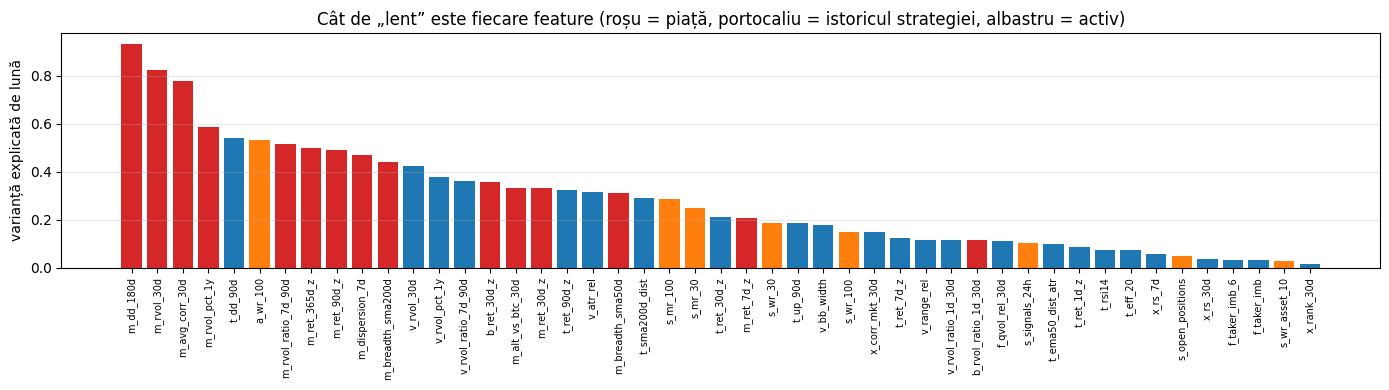

In [8]:
month = dev["decision_time"].dt.strftime("%Y-%m")
clock = pd.Series({f: dev[f].groupby(month).transform("mean").var() / dev[f].var()
                   for fs in ["V", "T", "M", "R", "S", "F"] for f in FAMILIES[fs]}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
colors = ["tab:red" if f.startswith(("m_", "b_")) else "tab:orange" if f.startswith(("s_", "a_")) else "tab:blue" for f in clock.index]
ax.bar(range(len(clock)), clock.values, color=colors)
ax.set_xticks(range(len(clock)))
ax.set_xticklabels(clock.index, rotation=90, fontsize=7)
ax.set_ylabel("varianță explicată de lună")
ax.set_title("Cât de „lent” este fiecare feature (roșu = piață, portocaliu = istoricul strategiei, albastru = activ)")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

### Exemplu: de ce istoricul strategiei strică predicțiile la SuperTrend

`s_wr_100` (rata de câștig a ultimelor 100 de tranzacții SuperTrend închise) are două componente cu semne **opuse**:

* **în interiorul unei perioade**, după o serie bună urmează tranzacții mai slabe (win rate pe terțile descrescător în
  majoritatea ferestrelor);
* **între regimuri**, o perioadă bună persistă (efectul de *factor momentum*). În fereastra 2024-09 (bull market),
  `s_wr_100` a ieșit din intervalul văzut în antrenare, strategia a continuat să câștige, iar modelul a prezis „revenire la
  medie” și a pierdut masiv.

In [9]:
g = dev.loc[dev["strategy"].eq("SUPERTREND")]
rows = []
for w0, w1 in WINDOWS_B:
    train, test = g.loc[g["exit_time"] < w0], g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
    m = lr_model(0.03).fit(train[["s_wr_100"]], train["y"])
    p = m.predict_proba(test[["s_wr_100"]])[:, 1]
    terc = lambda d: d.groupby(pd.qcut(d["s_wr_100"].rank(method="first"), 3, labels=False))["y"].mean().round(2).tolist()
    rows.append({"fereastră": str(w0.date()), "coeficient": m[-1].coef_[0][0], "win rate pe terțile (antrenare)": terc(train),
                 "win rate pe terțile (test)": terc(test),
                 "s_wr_100 în antrenare (5–95 %)": f"{train['s_wr_100'].quantile(.05):.2f}–{train['s_wr_100'].quantile(.95):.2f}",
                 "s_wr_100 în test (5–95 %)": f"{test['s_wr_100'].quantile(.05):.2f}–{test['s_wr_100'].quantile(.95):.2f}",
                 "win rate test": test["y"].mean(),
                 "Δ log loss": np.mean(ll(p, test["y"].to_numpy()) - ll(np.full(len(test), train["y"].mean()), test["y"].to_numpy()))})
pd.DataFrame(rows).set_index("fereastră").round(3)

,coeficient,win rate pe terțile (antrenare),win rate pe terțile (test),s_wr_100 în antrenare (5–95 %),s_wr_100 în test (5–95 %),win rate test,Δ log loss
fereastră,,,,,,,
2023-09-01,-0.264,"[0.51, 0.35, 0.31]","[0.41, 0.45, 0.33]",0.28–0.49,0.31–0.45,0.395,-0.002
2024-03-01,-0.239,"[0.48, 0.35, 0.34]","[0.45, 0.3, 0.4]",0.29–0.49,0.33–0.44,0.385,-0.004
2024-09-01,-0.239,"[0.48, 0.36, 0.33]","[0.58, 0.45, 0.41]",0.30–0.48,0.41–0.57,0.483,0.089
2025-03-01,-0.156,"[0.48, 0.35, 0.37]","[0.6, 0.31, 0.32]",0.30–0.52,0.31–0.48,0.412,-0.015
2025-09-01,-0.164,"[0.5, 0.35, 0.37]","[0.45, 0.43, 0.26]",0.30–0.51,0.34–0.50,0.377,-0.011
2026-03-01,-0.174,"[0.48, 0.37, 0.36]","[0.41, 0.46, 0.32]",0.30–0.51,0.23–0.45,0.396,0.022


### O rată de bază dinamică nu ajută

Dacă regimul de câștig persistă, o rată de câștig recentă (ultimele N tranzacții închise ale strategiei, amestecată cu prior-ul
static în proporția λ) ar trebui să bată prior-ul static. Nu se întâmplă: ferestrele scurte sunt zgomot, iar cele lungi
converg spre prior.

In [10]:
def recent_rate(g, n):
    ex = g.sort_values("exit_time")
    et, yc = ns(ex["exit_time"]), np.r_[0, ex["y"].cumsum().to_numpy()]
    k = np.searchsorted(et, ns(g["decision_time"]), side="left")
    lo = np.maximum(k - n, 0)
    return pd.Series(np.where(k - lo >= min(n, 50), (yc[k] - yc[lo]) / np.maximum(k - lo, 1), np.nan), index=g.index)


rows = {}
base = []
for s, g in dev.groupby("strategy"):
    for w0, w1 in WINDOWS_B:
        test = g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
        base.append(pd.DataFrame({"row": test.index, "prior": g.loc[g["exit_time"] < w0, "y"].mean(), "window": w0}))
base = pd.concat(base).join(dev[["strategy", "asset", "decision_time", "exit_time", "trade_return", "y"]], on="row")
for n in [50, 100, 200, 400, 800]:
    rr = pd.concat([recent_rate(g, n) for _, g in dev.groupby("strategy")])
    for lam in [1.0, 0.5, 0.25]:
        p = lam * rr.loc[base["row"]].to_numpy() + (1 - lam) * base["prior"].to_numpy()
        rows[(f"ultimele {n}", lam)] = summary_line(base.assign(p=np.where(np.isnan(p), base["prior"], p)))
pd.DataFrame(rows).T.style.format({"Δ toate": "{:+.4f}", "IC jos": "{:+.4f}", "IC sus": "{:+.4f}"})

## 2. Probabilitatea de câștig este aproape constantă; randamentul nu este

Câștigul maxim de log loss posibil cu un feature care are corelația ρ cu eticheta binară (rată de bază p) este aproximativ
½·(ρ²/(p(1−p)))·p(1−p) = ρ²/2. Pentru ρ ≈ 0.05, tipic la RSI, Donchian și SuperTrend, asta înseamnă ~0.001: sub ce se poate
detecta cu câteva mii de tranzacții. De aceea ne uităm la **randamentul mediu** pe chintile. El contează economic, iar
corelația Spearman cu randamentul înșală: când 70 % din tranzacții pierd, volatilitatea mare face pierderile mai mari, iar
rangurile scad chiar dacă media nu se schimbă.

Tabelul arată randamentul mediu (bps) pe chintile ale câtorva features, separat pe cele două jumătăți ale lui B.

In [11]:
MID = pd.Timestamp("2024-03-01", tz="UTC")
QF = ["v_rvol_30d", "m_rvol_30d", "v_atr_rel", "t_rsi14", "s_wr_100", "m_alt_vs_btc_30d"]
rows = []
for s, g in dev.groupby("strategy"):
    for f in QF:
        row = {"strategie": s, "feature": f}
        for h, gg in [("H1", g.loc[g["decision_time"] < MID]), ("H2", g.loc[g["decision_time"] >= MID])]:
            gg = gg.loc[gg[f].notna()]
            q = pd.qcut(gg[f].rank(method="first"), 5, labels=False)
            row[f"{h} bps Q1→Q5"] = "  ".join(f"{v:+.0f}" for v in gg.groupby(q)["trade_return"].mean() * 1e4)
            row[f"{h} win Q1→Q5"] = " ".join(f"{v:.2f}" for v in gg.groupby(q)["y"].mean())
        rows.append(row)
pd.DataFrame(rows).set_index(["strategie", "feature"])

H1 bps Q1→Q5              H1 win Q1→Q5                  H2 bps Q1→Q5              H2 win Q1→Q5
strategie  feature                                                                                                                         
DONCHIAN   v_rvol_30d         +179  +168  +265  +152  -27  0.62 0.49 0.54 0.52 0.44    +233  +129  +190  +9  +126  0.58 0.49 0.52 0.42 0.50
           m_rvol_30d          +386  +148  +92  -14  +122  0.67 0.54 0.42 0.47 0.50    +124  +291  -26  +230  +73  0.50 0.56 0.43 0.51 0.51
           v_atr_rel           +257  +221  +76  +243  -62  0.67 0.53 0.52 0.50 0.39    +111  +24  +227  +47  +279  0.51 0.46 0.55 0.47 0.51
           t_rsi14             +195  +84  +78  +132  +245  0.51 0.49 0.53 0.53 0.54     -4  +42  +145  +239  +266  0.46 0.45 0.57 0.51 0.51
           s_wr_100            +290  +164  +98  +198  -14  0.61 0.52 0.53 0.55 0.40   +342  -34  +383  +174  -177  0.55 0.38 0.63 0.53 0.41
           m_alt_vs_btc_30d   +228  +473  +187  -36  -115  0.60 0.57 0.59 0.45 0.40     +190  +304  +166  +26  +4  0.56 0.58 0.47 0.44 0.45
RSI        v_rvol_30d              +13  -17  +13  -7  -69  0.33 0.28 0.29 0.27 0.25        +69  +63  +43  +4  +59  0.30 0.30 0.31 0.28 0.31
           m_rvol_30d               +6  +27  +2  -52  -49  0.29 0.31 0.31 0.25 0.26      +112  +53  -13  +68  +18  0.31 0.33 0.28 0.31 0.26
           v_atr_rel               +27  +9  -27  -54  -21  0.35 0.30 0.25 0.26 0.27       +46  +62  +42  +37  +51  0.30 0.28 0.32 0.31 0.28
           t_rsi14                 -3  -42  -26  -37  +42  0.29 0.26 0.29 0.29 0.30      -11  +69  +30  +17  +131  0.24 0.33 0.26 0.26 0.38
           s_wr_100                -0  -26  -39  +46  -47  0.29 0.28 0.28 0.35 0.23       +6  +72  +150  -51  +61  0.32 0.32 0.36 0.20 0.28
           m_alt_vs_btc_30d        +8  -16  +47  -51  -54  0.33 0.27 0.31 0.27 0.24      +15  +188  +56  -51  +29  0.26 0.38 0.36 0.24 0.25
SUPERTREND v_rvol_30d             +129  +6  +48  +96  -84  0.38 0.40 0.41 0.37 0.42   +275  +201  +105  -91  -114  0.46 0.42 0.42 0.37 0.38
           m_rvol_30d         +227  +185  -123  -128  +32  0.39 0.45 0.33 0.36 0.44     +447  +203  -3  -209  -63  0.47 0.42 0.39 0.38 0.39
           v_atr_rel              +192  +30  -52  +15  +8  0.38 0.40 0.33 0.42 0.45     +196  +114  +95  +46  -76  0.45 0.39 0.39 0.41 0.41
           t_rsi14                -53  +96  -18  +73  +99  0.40 0.40 0.40 0.37 0.40    +128  +114  +35  -30  +129  0.45 0.44 0.42 0.35 0.38
           s_wr_100             +256  +119  -61  -113  -7  0.49 0.48 0.33 0.32 0.36     +304  +47  +86  +41  -101  0.48 0.46 0.40 0.36 0.35
           m_alt_vs_btc_30d    +274  +238  -30  -12  -274  0.47 0.48 0.39 0.33 0.31   +102  +221  -59  +273  -160  0.41 0.41 0.35 0.46 0.41
TIS        v_rvol_30d          +352  +140  +93  +26  -278  0.47 0.32 0.35 0.33 0.21   +867  +273  -78  -212  -223  0.39 0.31 0.29 0.21 0.19
           m_rvol_30d        +375  +439  -165  -108  -209  0.45 0.46 0.21 0.31 0.25  +978  +145  -144  -112  -240  0.27 0.46 0.28 0.22 0.16
           v_atr_rel           +231  +332  +97  -50  -276  0.42 0.39 0.38 0.25 0.24      +2  +496  +372  +8  -250  0.27 0.34 0.36 0.19 0.22
           t_rsi14              -30  -44  -59  +207  +259  0.28 0.22 0.32 0.39 0.47   -143  -71  -130  +336  +635  0.14 0.27 0.24 0.32 0.42
           s_wr_100          +306  +309  -162  -227  +105  0.47 0.42 0.22 0.20 0.37   +112  -66  -116  +891  -193  0.34 0.29 0.31 0.26 0.18
           m_alt_vs_btc_30d    +174  +490  -45  +31  -317  0.35 0.47 0.31 0.34 0.21   -209  +1187  -6  -111  -233  0.16 0.43 0.35 0.26 0.19

Efectele cele mai clare: la **TIS** și **SuperTrend**, chintila cu volatilitatea cea mai mare are randament mediu mult mai
slab în ambele jumătăți. La TIS, un RSI mare la semnal (momentum puternic) înseamnă tranzacții mai bune.

## 3. Două pârghii economice: dimensionarea și filtrarea

* **D1, dimensionare invers proporțională cu volatilitatea:** notional × clip(mediana din antrenare a `v_rvol_30d` /
  `v_rvol_30d`, 0.25, 4). Nu are niciun model și niciun parametru ajustat.
* **Filtre din meta-modele:** se acceptă tranzacția dacă p ≥ prior. Modelele de mai jos sunt **pooled** pe cele 4 strategii
  (o constantă pe strategie, pante comune), cu C ales intern. Le comparăm cu D1 și cu combinația D1 × filtru.

Pentru a vedea de unde vine efectul volatilității, separăm volatilitatea activului (V1) în componenta de piață (V7) și
componenta relativă: rangul transversal (V6) și raportul față de piață (V8).

In [12]:
tr["v_rel_mkt"] = np.log(tr["v_rvol_30d"] / tr["m_rvol_30d"])
dev = tr.loc[tr["period"].eq("B")]
inv_B = inverse_vol(dev, WINDOWS_B)
T_B = dev.loc[inv_B.index]
e = econ_compare(T_B, {"base": np.ones(len(T_B)), "D1 invers-vol": inv_B.to_numpy()})
per = pd.concat({s: econ_compare(T_B[T_B.strategy.eq(s)], {"base": np.ones(int(T_B.strategy.eq(s).sum())),
                                                          "D1 invers-vol": inv_B[T_B.strategy.eq(s)].to_numpy()}).loc["D1 invers-vol"]
                 for s in SS}, axis=1).T
print("D1 pe B, toate strategiile:")
display(e.round(3))
print("D1 pe B, pe strategii:")
per[["Sharpe", "Δ Sharpe", "IC jos", "IC sus", "bps / dolar"]].astype(float).round(3)

D1 pe B, toate strategiile:


,tranzacții,notional mediu ×,PnL (USD),Sharpe,Δ Sharpe,IC jos,IC sus,bps / dolar
variantă,,,,,,,,
base,4969,1.000,445551.247,1.126,0.000,0.0,0.000,89.666
D1 invers-vol,4969,1.307,838962.385,1.452,0.326,0.1,0.675,129.213


D1 pe B, pe strategii:


,Sharpe,Δ Sharpe,IC jos,IC sus,bps / dolar
RSI,0.951,0.013,-0.196,0.347,37.583
DONCHIAN,1.245,0.139,-0.066,0.331,186.129
TIS,0.798,0.159,0.012,0.710,336.133
SUPERTREND,1.224,0.540,0.171,0.857,140.019


In [13]:
for s in SS:
    tr["vol_x_" + s] = tr["v_rvol_30d"] * tr["is_" + s]
VARIANTS = {"V1 vol. activ": ["v_rvol_30d"], "V3 V1 + momentum TIS": ["v_rvol_30d", "tis_rsi", "tis_ema"],
            "V6 rang transversal vol.": ["xr_rvol_30d"], "V7 vol. piață": ["m_rvol_30d"],
            "V8 vol. activ / vol. piață": ["v_rel_mkt"], "V2 vol. × strategie": ["vol_x_" + s for s in SS]}
dev = tr.loc[tr["period"].eq("B")]
rows, preds_B = {}, {}
for name, fs in VARIANTS.items():
    pr = walk_forward(dev, WINDOWS_B, lambda s, fs=fs: DUM + fs, LR_GRID, pooled=True)
    preds_B[name] = pr
    T = pr.set_index("row")
    acc = (T["p"] >= T["prior"]).to_numpy()
    w = inv_B.loc[T.index].to_numpy()
    ec = econ_compare(T, {"base": np.ones(len(T)), "filtru": acc.astype(float), "D1 × filtru": w * acc})
    lift = random_lift(T, acc)
    sl = summary_line(pr)
    rows[name] = {"Δ log loss": sl["Δ toate"], "IC": f"[{sl['IC jos']:+.4f}, {sl['IC sus']:+.4f}]", "TIS": sl["TIS"],
                  "acceptate (%)": 100 * acc.mean(), "Δ Sharpe filtru": ec.loc["filtru", "Δ Sharpe"],
                  "IC filtru": f"[{ec.loc['filtru', 'IC jos']:+.2f}, {ec.loc['filtru', 'IC sus']:+.2f}]",
                  "Δ Sharpe D1 × filtru": ec.loc["D1 × filtru", "Δ Sharpe"], "lift vs aleator (USD)": lift["lift"],
                  "p lift": lift["p (aleator ≥ real)"]}
pd.DataFrame(rows).T

,Δ log loss,IC,TIS,acceptate (%),Δ Sharpe filtru,IC filtru,Δ Sharpe D1 × filtru,lift vs aleator (USD),p lift
V1 vol. activ,-0.001795,"[-0.0040, +0.0006]",-0.0080*,61.279936,0.42238,"[+0.04, +0.97]",0.52274,205914.083789,0.0
V3 V1 + momentum TIS,-0.002285,"[-0.0064, +0.0017]",-0.0118,60.313946,0.367578,"[-0.03, +0.90]",0.509167,210650.005954,0.0
V6 rang transversal vol.,-0.000575,"[-0.0013, +0.0001]",-0.0009,50.976052,-0.030137,"[-0.43, +0.35]",0.246163,38925.224974,0.195
V7 vol. piață,-0.002033,"[-0.0058, +0.0017]",-0.0079,65.667136,0.335016,"[-0.05, +0.86]",0.473294,201658.969248,0.0
V8 vol. activ / vol. piață,-0.000199,"[-0.0011, +0.0007]",-0.0008,48.48058,-0.111049,"[-0.59, +0.28]",0.215676,1867.137908,0.476
V2 vol. × strategie,-0.000268,"[-0.0019, +0.0015]",-0.0059,58.22097,-0.203281,"[-0.59, +0.06]",-0.028024,-29178.804521,0.765


Pe B, filtrul cu un singur feature (V1, volatilitatea activului) bate clar selecția aleatoare și ridică Sharpe-ul, deși
câștigul de log loss e minuscul. Asta confirmă că valoarea economică a unui filtru nu se citește din log loss. Dar
**efectul vine din volatilitatea pieței** (V7 face aproape cât V1), nu din cea relativă (V6, V8 nu fac nimic). E deci un
efect de regim, cu puține episoade independente. Pantele separate pe strategie (V2) supra-învață.

# Specificația înghețată

Scrisă **înainte** de orice rulare pe A sau C (amprenta SHA-256 a fișierului de specificație:
`fa6fbdaa486689939eea814c9b9f68431c024e8230dcb8eae5b9562ab3b46a2d`).

* **Date:** ca mai sus. **Etichetă:** `trade_return > 0`.
* **Stratul de probabilitate**, pooled pe cele 4 strategii, regresie logistică cu imputare mediană și `QuantileTransformer`,
  C ales intern din {0.003, 0.01, 0.03, 0.1, 0.3}, abținere → prior:
  * **S1:** constante pe strategie + `v_rvol_30d`;
  * **S2:** S1 + `t_rsi14`·[TIS] + `t_ema50_dist_atr`·[TIS].
* **Stratul de decizie:** D0 toate tranzacțiile, aceeași mărime; **D1** dimensionare invers-vol; **D2** filtru p ≥ prior;
  **D3** D1 × D2.
* **Evaluare, o singură rulare:** A = ferestre de 6 luni din 2019-03 până în 2021-08, antrenare pe tot ce s-a închis înainte;
  C = 2026-09-01 → 2026-11-19, antrenare pe tot ce s-a închis înainte de 2026-09-01; B ca referință.
* **Așteptări pre-înregistrate:** dacă efectul e real, D2/D3 bat D0 și selecția aleatoare pe A, iar câștigul de log loss e
  mic (~−0.002). **Riscul principal:** efectul e de regim al volatilității pieței; anul 2021 (volatilitate mare, trenduri
  puternice) este cazul advers.

# Partea II — evaluarea finală pe A și C (o singură rulare)

In [14]:
SYSTEMS = {"S1": DUM + ["v_rvol_30d"], "S2": DUM + ["v_rvol_30d", "tis_rsi", "tis_ema"]}
EVAL = {"A (nevăzută, 2019-03 → 2021-08)": (tr, WINDOWS_A, None),
        "C (nevăzută, date noi 2026-09 → 2026-11)": (tr, WINDOWS_C, None),
        "B (dezvoltare, referință)": (tr.loc[tr["period"].eq("B")], WINDOWS_B, A_END)}
final = {}
for pname, (data, windows, tstart) in EVAL.items():
    preds = {k: walk_forward(data, windows, lambda s, f=f: f, LR_GRID, pooled=True, train_start=tstart)
             for k, f in SYSTEMS.items()}
    inv = inverse_vol(data, windows, tstart)
    final[pname] = (preds, inv)

prob = pd.concat({(p, k): delta_table(pr) for p, (preds, _) in final.items() for k, pr in preds.items()})
prob.round(4)

n  Δ log loss  IC jos  IC sus  P(Δ<0)
                                            strategie                                           
A (nevăzută, 2019-03 → 2021-08)          S1 DONCHIAN     539      0.0156  0.0041  0.0329  0.0005
                                            RSI         1497      0.0002 -0.0014  0.0022  0.4240
                                            SUPERTREND   821      0.0002 -0.0010  0.0012  0.3175
                                            TIS          357      0.0007 -0.0025  0.0045  0.3710
                                            TOATE       3214      0.0029  0.0008  0.0057  0.0000
                                         S2 DONCHIAN     539      0.0151  0.0037  0.0324  0.0015
                                            RSI         1497      0.0003 -0.0014  0.0023  0.3995
                                            SUPERTREND   821      0.0002 -0.0011  0.0012  0.3270
                                            TIS          357      0.0017 -0.0034  0.0073  0.2595
                                            TOATE       3214      0.0029  0.0008  0.0058  0.0000
C (nevăzută, date noi 2026-09 → 2026-11) S1 DONCHIAN      46      0.0029 -0.0007  0.0822  0.2345
                                            RSI          119      0.0019  0.0008  0.0226  0.0000
                                            SUPERTREND   113      0.0007 -0.0057  0.0169  0.3695
                                            TIS           41     -0.0065 -0.0101 -0.0002  1.0000
                                            TOATE        319      0.0006 -0.0005  0.0179  0.3050
                                         S2 DONCHIAN      46      0.0028 -0.0007  0.0789  0.2345
                                            RSI          119      0.0019  0.0008  0.0218  0.0000
                                            SUPERTREND   113      0.0007 -0.0055  0.0162  0.3695
                                            TIS           41     -0.0345 -0.0591 -0.0204  1.0000
                                            TOATE        319     -0.0031 -0.0125  0.0172  0.8505
B (dezvoltare, referință)                S1 DONCHIAN     782     -0.0021 -0.0071  0.0031  0.7545
                                            RSI         2070      0.0002 -0.0022  0.0028  0.4390
                                            SUPERTREND  1496     -0.0019 -0.0052  0.0017  0.8510
                                            TIS          621     -0.0080 -0.0144 -0.0015  0.9915
                                            TOATE       4969     -0.0018 -0.0040  0.0006  0.9205
                                         S2 DONCHIAN     782     -0.0022 -0.0071  0.0029  0.7745
                                            RSI         2070      0.0002 -0.0022  0.0027  0.4420
                                            SUPERTREND  1496     -0.0018 -0.0051  0.0016  0.8515
                                            TIS          621     -0.0118 -0.0409  0.0156  0.7850
                                            TOATE       4969     -0.0023 -0.0064  0.0017  0.8520

In [15]:
def economics(pname, scope="TOATE"):
    preds, inv = final[pname]
    P1, P2 = preds["S1"].set_index("row"), preds["S2"].set_index("row")
    ix = P1.index if scope == "TOATE" else P1.index[P1["strategy"].eq(scope)]
    T = P1.loc[ix, ["strategy", "trade_return", "exit_time"]]
    a1 = (P1.loc[ix, "p"] >= P1.loc[ix, "prior"]).to_numpy()
    a2 = (P2.loc[ix, "p"] >= P2.loc[ix, "prior"]).to_numpy()
    w = inv.loc[ix].to_numpy()
    e = econ_compare(T, {"base": np.ones(len(T)), "D1 invers-vol": w, "D2 filtru S1": a1.astype(float),
                         "D3 invers-vol × filtru S1": w * a1, "D2 filtru S2": a2.astype(float),
                         "D3 invers-vol × filtru S2": w * a2})
    lifts = pd.DataFrame({"filtru S1": random_lift(T, a1), "filtru S2": random_lift(T, a2)}).T
    return e, lifts


for pname in final:
    e, lifts = economics(pname)
    print("=" * 30, pname, "— toate strategiile")
    display(e.round(3))
    display(lifts.round(3))

============================== A (nevăzută, 2019-03 → 2021-08) — toate strategiile


,tranzacții,notional mediu ×,PnL (USD),Sharpe,Δ Sharpe,IC jos,IC sus,bps / dolar
variantă,,,,,,,,
base,3214,1.000,860405.249,1.705,0.000,0.000,0.000,267.705
D1 invers-vol,3214,0.979,803483.861,2.111,0.406,0.087,0.725,255.280
D2 filtru S1,1794,1.000,375932.190,1.342,-0.363,-0.806,0.268,209.550
D3 invers-vol × filtru S1,1794,0.950,372944.985,1.583,-0.122,-0.524,0.425,218.919
D2 filtru S2,1775,1.000,334838.563,1.378,-0.327,-0.856,0.154,188.641
D3 invers-vol × filtru S2,1775,0.961,337840.773,1.502,-0.203,-0.678,0.251,197.965


,PnL acceptate,PnL aleator (medie),lift,p (aleator ≥ real)
filtru S1,375932.190,471939.401,-96007.211,0.978
filtru S2,334838.563,430407.018,-95568.455,0.948


============================== C (nevăzută, date noi 2026-09 → 2026-11) — toate strategiile


,tranzacții,notional mediu ×,PnL (USD),Sharpe,Δ Sharpe,IC jos,IC sus,bps / dolar
variantă,,,,,,,,
base,319,1.000,10127.764,0.376,0.000,NaN,NaN,31.748
D1 invers-vol,319,1.293,8421.391,0.278,-0.099,NaN,NaN,20.418
D2 filtru S1,206,1.000,10565.962,0.617,0.241,NaN,NaN,51.291
D3 invers-vol × filtru S1,206,1.553,8853.685,0.383,0.007,NaN,NaN,27.669
D2 filtru S2,200,1.000,15511.458,0.829,0.453,NaN,NaN,77.557
D3 invers-vol × filtru S2,200,1.531,12758.198,0.538,0.161,NaN,NaN,41.680


,PnL acceptate,PnL aleator (medie),lift,p (aleator ≥ real)
filtru S1,10565.962,5548.951,5017.011,0.262
filtru S2,15511.458,4775.885,10735.573,0.082


============================== B (dezvoltare, referință) — toate strategiile


,tranzacții,notional mediu ×,PnL (USD),Sharpe,Δ Sharpe,IC jos,IC sus,bps / dolar
variantă,,,,,,,,
base,4969,1.000,445551.247,1.126,0.000,0.000,0.000,89.666
D1 invers-vol,4969,1.307,838962.385,1.452,0.326,0.100,0.675,129.213
D2 filtru S1,3045,1.000,480411.022,1.549,0.422,0.036,0.966,157.770
D3 invers-vol × filtru S1,3045,1.636,865117.692,1.649,0.523,0.115,1.166,173.694
D2 filtru S2,2997,1.000,473116.564,1.494,0.368,-0.033,0.899,157.863
D3 invers-vol × filtru S2,2997,1.631,864463.855,1.635,0.509,0.099,1.171,176.829


,PnL acceptate,PnL aleator (medie),lift,p (aleator ≥ real)
filtru S1,480411.022,274496.938,205914.084,0.0
filtru S2,473116.564,262466.558,210650.006,0.0


In [16]:
rows = []
for pname in final:
    for s in SS:
        e, lifts = economics(pname, s)
        rows.append({"perioadă": pname.split(" ")[0], "strategie": s, "n": int(e.loc["base", "tranzacții"]),
                     "Sharpe bază": e.loc["base", "Sharpe"], "Δ Sharpe D1": e.loc["D1 invers-vol", "Δ Sharpe"],
                     "IC D1": f"[{e.loc['D1 invers-vol', 'IC jos']:+.2f}, {e.loc['D1 invers-vol', 'IC sus']:+.2f}]",
                     "Δ Sharpe D3 (S1)": e.loc["D3 invers-vol × filtru S1", "Δ Sharpe"],
                     "lift filtru S1 (USD)": lifts.loc["filtru S1", "lift"], "p lift S1": lifts.loc["filtru S1", "p (aleator ≥ real)"]})
pd.DataFrame(rows).set_index(["perioadă", "strategie"]).round(3)

n  Sharpe bază  Δ Sharpe D1           IC D1  Δ Sharpe D3 (S1)  lift filtru S1 (USD)  p lift S1
perioadă strategie                                                                                                    
A        RSI         1497        1.375        0.070  [-0.30, +0.37]            -0.138            -29618.015      0.849
         DONCHIAN     539        2.244        0.237  [-0.26, +0.59]            -1.206             17938.321      0.170
         TIS          357        1.381        0.194  [-0.04, +0.49]             0.212            -28567.031      0.900
         SUPERTREND   821        0.598        0.651  [-0.01, +1.10]            -0.332            -55748.602      0.974
C        RSI          119        0.918       -0.215    [+nan, +nan]             0.146              2442.076      0.214
         DONCHIAN      46        1.947       -0.563    [+nan, +nan]            -0.824               728.104      0.419
         TIS           41        0.759        0.147    [+nan, +nan]             0.391               627.415      0.398
         SUPERTREND   113       -0.535       -0.200    [+nan, +nan]            -0.151              1134.162      0.428
B        RSI         2070        0.938        0.013  [-0.20, +0.35]            -0.064              1135.015      0.470
         DONCHIAN     782        1.106        0.139  [-0.07, +0.33]             0.179             23598.673      0.033
         TIS          621        0.639        0.159  [+0.01, +0.71]             0.257             78951.014      0.000
         SUPERTREND  1496        0.684        0.540  [+0.17, +0.86]             0.988            101465.475      0.000

## Verificări de robustețe pentru D1 (după îngheț, descriptive)

Dimensionarea invers-vol este singura componentă care a trecut testul pe A. Verificăm dacă depinde de câteva tranzacții
extreme, cum arată pe ani, ce se întâmplă cu altă măsură a volatilității (ATR/preț) și cum se schimbă riscul lunar.

In [17]:
rows, years = [], []
for pname, data, windows, tstart in [("A", tr, WINDOWS_A, None), ("B", tr.loc[tr["period"].eq("B")], WINDOWS_B, A_END)]:
    inv = inverse_vol(data, windows, tstart)
    T = data.loc[inv.index].assign(w=inv)
    q1, q99 = T["trade_return"].quantile([0.01, 0.99])
    tails = T.loc[(T["trade_return"] > q1) & (T["trade_return"] < q99)]
    inv_atr = inverse_vol(data, windows, tstart, col="v_atr_rel")
    for nm, X, w in [("toate tranzacțiile", T, T["w"]), ("fără 1 % din cozi", tails, tails["w"]),
                     ("ATR/preț în loc de vol. 30d", T, inv_atr.loc[T.index])]:
        e = econ_compare(X, {"base": np.ones(len(X)), "D1": w.to_numpy()}).loc["D1"]
        rows.append({"perioadă": pname, "verificare": nm, "Sharpe bază": e["Sharpe"] - e["Δ Sharpe"], "Sharpe D1": e["Sharpe"],
                     "Δ Sharpe": e["Δ Sharpe"], "IC": f"[{e['IC jos']:+.2f}, {e['IC sus']:+.2f}]"})
    for nm, w in [("bază", np.ones(len(T))), ("D1", T["w"].to_numpy())]:
        m = monthly(NOTIONAL * w * T["trade_return"].to_numpy(), T["exit_time"])
        eq = m.cumsum()
        rows.append({"perioadă": pname, "verificare": f"risc lunar ({nm})", "PnL lunar mediu": m.mean(), "sd lunar": m.std(),
                     "drawdown maxim": (eq - eq.cummax()).min(), "notional mediu ×": w.mean()})
    for yv, X in T.groupby(T["exit_time"].dt.year):
        m0, m1 = monthly(NOTIONAL * X["trade_return"], X["exit_time"]), monthly(NOTIONAL * X["w"] * X["trade_return"], X["exit_time"])
        years.append({"perioadă": pname, "an ieșire": yv, "tranzacții": len(X), "Sharpe bază": sharpe(m0.to_numpy()),
                      "Sharpe D1": sharpe(m1.to_numpy())})
display(pd.DataFrame(rows).set_index(["perioadă", "verificare"]).round(2))
pd.DataFrame(years).set_index(["perioadă", "an ieșire"]).round(2)

Sharpe bază  Sharpe D1  Δ Sharpe              IC  PnL lunar mediu  sd lunar  drawdown maxim  notional mediu ×
perioadă verificare                                                                                                                                
A        toate tranzacțiile                  1.70       2.11      0.41  [+0.09, +0.72]              NaN       NaN             NaN               NaN
         fără 1 % din cozi                   1.83       2.23      0.40  [+0.08, +0.71]              NaN       NaN             NaN               NaN
         ATR/preț în loc de vol. 30d         1.70       2.23      0.52  [+0.16, +0.93]              NaN       NaN             NaN               NaN
         risc lunar (bază)                    NaN        NaN       NaN             NaN         27755.01  56394.20       -26744.66              1.00
         risc lunar (D1)                      NaN        NaN       NaN             NaN         25918.83  42532.42       -26613.32              0.98
B        toate tranzacțiile                  1.13       1.45      0.33  [+0.10, +0.68]              NaN       NaN             NaN               NaN
         fără 1 % din cozi                   0.86       1.27      0.41  [+0.17, +0.76]              NaN       NaN             NaN               NaN
         ATR/preț în loc de vol. 30d         1.13       1.48      0.36  [+0.12, +0.70]              NaN       NaN             NaN               NaN
         risc lunar (bază)                    NaN        NaN       NaN             NaN         12376.42  38069.39       -47979.97              1.00
         risc lunar (D1)                      NaN        NaN       NaN             NaN         23304.51  55587.12       -47404.53              1.31

tranzacții  Sharpe bază  Sharpe D1
perioadă an ieșire                                    
A        2019              629         0.59       0.88
         2020             1331         2.45       2.57
         2021             1254         2.60       2.74
B        2023              684         3.90       3.64
         2024             1723         1.40       1.70
         2025             1542         0.50       0.76
         2026             1020         0.74       1.19

## De ce filtrul a eșuat pe A

Win rate-ul și randamentul mediu pe terțile ale volatilității pieței (terțile fixate pe tot eșantionul).

In [18]:
q = tr["m_rvol_30d"].quantile([1 / 3, 2 / 3]).to_list()
tr["vol. piață"] = pd.cut(tr["m_rvol_30d"], [-np.inf, *q, np.inf], labels=["mică", "medie", "mare"])
sub = tr.loc[tr["period"].isin(["A", "B"])]
display(sub.groupby(["period", "vol. piață"], observed=True).agg(
    tranzacții=("y", "size"), win_rate=("y", "mean"), randament_mediu_bps=("trade_return", lambda r: 1e4 * r.mean())).round(3))
sub.groupby(["period", "strategy", "vol. piață"], observed=True)["y"].mean().unstack().round(2)

tranzacții  win_rate  randament_mediu_bps
period vol. piață                                           
A      mică               621     0.414              282.247
       medie             1205     0.378              244.612
       mare              2034     0.358              216.844
B      mică              3224     0.392              190.744
       medie             2691     0.333              -50.013
       mare              2001     0.346              -10.477

vol. piață         mică  medie  mare
period strategy                     
A      DONCHIAN    0.61   0.60  0.52
       RSI         0.29   0.31  0.30
       SUPERTREND  0.52   0.39  0.34
       TIS         0.36   0.33  0.42
B      DONCHIAN    0.55   0.45  0.52
       RSI         0.30   0.30  0.26
       SUPERTREND  0.44   0.35  0.43
       TIS         0.42   0.23  0.24

## Concluzii

Cifrele de mai jos vin din output-urile de deasupra, cu excepția corelațiilor univariate ρ, calculate în timpul dezvoltării. Rularea este deterministă (seed-uri fixe, date în cache cu
`DATA_END` fix).

**1. Probabilitatea de câștig nu se lasă prezisă peste prior, nici cu features din toate familiile.**
* Pe B, unde s-a făcut dezvoltarea, niciun set de features nu bate prior-ul semnificativ. Familiile de piață (M) și
  istoricul strategiei (S) strică predicțiile (+0.033 și +0.022 log loss), pentru că sunt **ceasuri de regim**: luna
  calendaristică explică până la 93 % din varianța lor (graficul cu bare). Numărul efectiv de observații este deci numărul de regimuri, iar modelul
  devine supra-încrezător.
* Ranguri transversale, care elimină componenta comună tuturor activelor, rate de bază dinamice (ultimele 50–800 de
  tranzacții) și modele mici, constrânse: niciuna nu bate prior-ul.
* Pentru RSI, Donchian și SuperTrend, corelațiile features cu eticheta sunt de ordinul 0.05. Câștigul maxim posibil de log
  loss este atunci ~ρ²/2 ≈ 0.001, sub ce se poate detecta cu câteva mii de tranzacții. Doar TIS are relații mai puternice
  (RSI la semnal, volatilitate; vezi tabelul pe chintile), și doar pe B.
* **Sistemul înghețat** (S1: constante pe strategie + volatilitatea pe 30 de zile; S2: plus momentum la TIS) dă pe B
  −0.0018 [−0.0040, +0.0006], dar pe **A, nevăzută, +0.0029 [+0.0008, +0.0057]**, adică semnificativ **mai rău** decât prior-ul
  (mai ales Donchian, +0.016). Pe **C** (319 tranzacții): S1 +0.0006, S2 −0.0031 [−0.0125, +0.0172]. Nicio dovadă de câștig.

**2. Filtrul de volatilitate a fost un efect de regim și s-a inversat.**
* Pe B, filtrul „p ≥ prior” al lui S1 accepta 61 % din tranzacții, bătea selecția aleatoare cu +206k USD (p < 0.001) și
  ridica Sharpe-ul cu +0.42 [+0.04, +0.97]. Descompunerea a arătat însă că efectul vine din **volatilitatea pieței** (V7), nu
  din cea relativă a activului (V6, V8), deci din puține episoade.
* Pe **A** același filtru e **mai rău decât selecția aleatoare** (−96k USD, p = 0.98; Sharpe −0.36). Explicația e în ultimul
  tabel: pe A, chiar și tranzacțiile din volatilitate mare aveau randament mediu de +217 bps (față de +282 bps în volatilitate
  mică), deci erau profitabile. Pe B aveau −10 bps. Un filtru pierde bani ori de câte ori elimină tranzacții cu randament
  așteptat pozitiv. În plus, pragul este fixat de nivelul volatilității din antrenare, deci când volatilitatea se mută
  filtrul devine un filtru de calendar.
* Pe **C** filtrele au lift pozitiv (S1 +5k USD, p = 0.26; S2 +10.7k, p = 0.08), dar cu 319 tranzacții în 3 luni asta nu
  înseamnă nimic, mai ales după eșecul de pe A.

**3. Ce funcționează: dimensionarea invers proporțională cu volatilitatea (D1).**
* Regula: notional × clip(mediana din antrenare a volatilității pe 30 de zile / volatilitatea activului la semnal, 0.25, 4).
  Nu are model și nu are parametri ajustați pe date. Limitele 0.25–4 au fost fixate dinainte.
* **B:** Sharpe 1.13 → 1.45 (+0.33 [+0.10, +0.68]); câștig la SuperTrend (+0.54) și TIS (+0.16), mai mic la Donchian, zero
  la RSI.
* **A (nevăzută):** Sharpe 1.70 → **2.11 (+0.41 [+0.09, +0.73])**; direcția e aceeași la toate patru strategiile (SuperTrend
  +0.65, Donchian +0.24, TIS +0.19, RSI +0.07), deși fiecare interval individual include 0.
* **Robustețe:** câștigul rămâne și fără 1 % din tranzacțiile extreme (A +0.40, B +0.41), e mai mare cu ATR/preț în loc de
  volatilitatea realizată (A +0.52, B +0.36) și apare în 6 din 7 ani (excepția: 2023). Pe A riscul lunar scade (deviația
  standard 56k → 43k USD) la un randament mediu aproape egal.
* **De ce:** mărimea câștigurilor și pierderilor crește cu volatilitatea, dar randamentul pe dolar investit nu crește (B:
  89.7 → 129.2 bps pe dolar după redimensionare; A: 267.7 → 255.3). Egalizarea riscului pe tranzacție scade varianța mai mult
  decât randamentul. Este mecanismul portofoliilor gestionate după volatilitate (Moreira și Muir, 2017).
* **C:** −0.10 Sharpe pe 3 luni, fără interval de încredere calculabil. Nu confirmă și nu infirmă.

**Răspunsul la întrebare.** Un meta-model care să bată prior-ul *ca probabilitate de câștig* nu există pe aceste date: ce
părea semnal pe B era regim și nu s-a transferat pe A. Un sistem care **deduce din features și îmbunătățește strategia peste
prior** există însă, sub formă de **dimensionare**, nu de filtru: volatilitatea activului la momentul semnalului spune
cât capital să aloci, nu dacă să intri. Este singura componentă confirmată pe o perioadă pe care nici eu, nici
notebook-urile anterioare nu o văzuserăm.

**Limite.**
* A este *înaintea* lui B în timp. Walk-forward-ul din A folosește doar trecutul, deci testul e corect, dar verifică
  generalitatea pe un alt regim (2019–2021), nu simulează sistemul live după 2026.
* C are doar 3 luni. Partea a II-a poate fi rerulată pe măsură ce apar date noi: se mută `DATA_END`, fără nicio altă
  schimbare. Abia după 6–12 luni C devine informativ.
* Sharpe-ul este calculat pe PnL lunar cu notional per tranzacție, fără constrângeri de capital, fără compunere și cu costuri
  fixe de 5 bps independent de mărime. La 2 500–40 000 USD per tranzacție impactul suplimentar e neglijabil, dar un portofoliu
  real ar avea și limite de expunere totală.
* Pe B s-au încercat multe variante. Alegerile înghețate sunt deci selectate, iar rezultatele de pe B sunt optimiste; de
  aceea contează doar A și C.
* Cele 20 de active există și azi (efect de supraviețuire posibil).

**Ce merită făcut mai departe.**
* Rularea părții a II-a pe C extins (aceeași specificație înghețată) peste câteva luni.
* Testarea, **doar pe date noi**, a dimensionării cu ATR/preț (care a ieșit mai bine pe A și B, dar a fost observată după
  îngheț) și a unei ținte de volatilitate la nivel de portofoliu.
* Pentru meta-labeling de probabilitate pe aceste strategii de 4h: nu merită alte seturi de features pe aceleași date.
  Singura cale onestă ar fi istorii mult mai lungi, cu multe regimuri independente, sau alte etichete și alte strategii primare.